# Problem 1 - RNN, LSTM and GRU

Chosen settings (assumed - the variants table was not in the brief): **h = 32** for every recurrent model; seeds **11, 23, 42**. Student ID ends in 8 (even) so the individual ablation (c) is **gradient clipping (norm 1.0 vs none) for the vanilla RNN at T = 200**.

Budget (same for every model in a comparison): Adam, lr 1e-3, batch 64, HAR 20 epochs, adding problem 30 epochs, gradient-norm clipping 1.0 everywhere except the clipping ablation. The epoch with the best validation score is used for test evaluation.

Outputs go to `figures/` and are appended (idempotently) to `../results.csv`.

In [1]:
import numpy as np
import torch
import torch.nn as nn

HIDDEN_SIZE = 32
SEEDS = (11, 23, 42)


def make_adding(n, T, seed):
    rng = np.random.default_rng(seed)
    x = np.zeros((n, T, 2), dtype=np.float32)
    x[:, :, 0] = rng.random((n, T))
    i1 = rng.integers(0, T // 2, n)
    i2 = rng.integers(T // 2, T, n)
    x[np.arange(n), i1, 1] = 1
    x[np.arange(n), i2, 1] = 1
    y = x[np.arange(n), i1, 0] + x[np.arange(n), i2, 0]
    return x, y.astype(np.float32)


def validate_adding_problem(x, y):
    if x.ndim != 3 or x.shape[-1] != 2:
        raise ValueError(f'Expected shape (n, T, 2), got {x.shape}')
    marks = x[:, :, 1] > 0.5
    if not np.all(marks.sum(axis=1) == 2):
        raise AssertionError('Each sequence must have exactly two markers')
    if not np.all(marks[:, :x.shape[1] // 2].sum(axis=1) == 1):
        raise AssertionError('The left half must have exactly one marker')
    if not np.all(marks[:, x.shape[1] // 2:].sum(axis=1) == 1):
        raise AssertionError('The right half must have exactly one marker')
    expected = (x[:, :, 0] * x[:, :, 1]).sum(axis=1)
    if not np.allclose(y, expected):
        raise AssertionError('Targets must equal the sum of marked values')
    return True


def count_recurrent_parameters(input_size, hidden_size, cell_type):
    gates = {'rnn': 1, 'lstm': 4, 'gru': 3}[cell_type.lower()]
    return gates * (input_size * hidden_size + hidden_size * hidden_size + hidden_size)


def _rnn_from_weights(x, layer, h0):
    h = h0
    outputs = []
    for xt in x.unbind(dim=1):
        h = torch.tanh(xt @ layer.weight_ih_l0.T + layer.bias_ih_l0
                       + h @ layer.weight_hh_l0.T + layer.bias_hh_l0)
        outputs.append(h)
    return torch.stack(outputs, dim=1), h


def _lstm_from_weights(x, layer, h0, c0):
    h, c = h0, c0
    outputs = []
    for xt in x.unbind(dim=1):
        gates = (xt @ layer.weight_ih_l0.T + layer.bias_ih_l0
                 + h @ layer.weight_hh_l0.T + layer.bias_hh_l0)
        i, f, g, o = gates.chunk(4, dim=-1)
        i, f, o = i.sigmoid(), f.sigmoid(), o.sigmoid()
        g = g.tanh()
        c = f * c + i * g
        h = o * c.tanh()
        outputs.append(h)
    return torch.stack(outputs, dim=1), h, c


def _gru_from_weights(x, layer, h0):
    h = h0
    outputs = []
    w_ir, w_iz, w_in = layer.weight_ih_l0.chunk(3, dim=0)
    w_hr, w_hz, w_hn = layer.weight_hh_l0.chunk(3, dim=0)
    b_ir, b_iz, b_in = layer.bias_ih_l0.chunk(3, dim=0)
    b_hr, b_hz, b_hn = layer.bias_hh_l0.chunk(3, dim=0)
    for xt in x.unbind(dim=1):
        reset = (xt @ w_ir.T + b_ir + h @ w_hr.T + b_hr).sigmoid()
        update = (xt @ w_iz.T + b_iz + h @ w_hz.T + b_hz).sigmoid()
        new = (xt @ w_in.T + b_in + reset * (h @ w_hn.T + b_hn)).tanh()
        h = (1 - update) * new + update * h
        outputs.append(h)
    return torch.stack(outputs, dim=1), h


def check_backwards_compatibility(hidden_size):
    torch.manual_seed(7)
    x = torch.randn(5, 6, 9)
    h0 = torch.randn(5, hidden_size)
    c0 = torch.randn(5, hidden_size)
    with torch.no_grad():
        rnn = nn.RNN(9, hidden_size, batch_first=True)
        ref, _ = rnn(x, h0.unsqueeze(0))
        actual, _ = _rnn_from_weights(x, rnn, h0)
        torch.testing.assert_close(actual, ref, atol=1e-5, rtol=1e-5)

        lstm = nn.LSTM(9, hidden_size, batch_first=True)
        ref, _ = lstm(x, (h0.unsqueeze(0), c0.unsqueeze(0)))
        actual, _, _ = _lstm_from_weights(x, lstm, h0, c0)
        torch.testing.assert_close(actual, ref, atol=1e-5, rtol=1e-5)

        gru = nn.GRU(9, hidden_size, batch_first=True)
        ref, _ = gru(x, h0.unsqueeze(0))
        actual, _ = _gru_from_weights(x, gru, h0)
        torch.testing.assert_close(actual, ref, atol=1e-5, rtol=1e-5)
    return True


print('Chosen hidden size:', HIDDEN_SIZE)
print('Three-run seeds:', SEEDS)

Chosen hidden size: 32
Three-run seeds: (11, 23, 42)


## UCI HAR dataset: download, load, split, and normalize

The first run downloads the official UCI HAR archive into a local `data/` cache beside this notebook and extracts it. The loader stacks the nine inertial-signal channels in the assignment's required order. For each seed, four subjects are held out from the original training subjects for validation. Per-channel mean and standard deviation are fitted on training subjects only, then applied to validation and the untouched official test set. Activity labels are converted from 1-6 to 0-5 for PyTorch classifiers. The archive is not included in the submission.

Dataset root: /content/har/UCI HAR Dataset
Train: (5891, 128, 9) (5891,)
Validation: (1461, 128, 9) (1461,) held-out subjects: [5, 17, 25, 28]
Official test: (2947, 128, 9) (2947,)
Input feature count: 9 | sequence length: 128


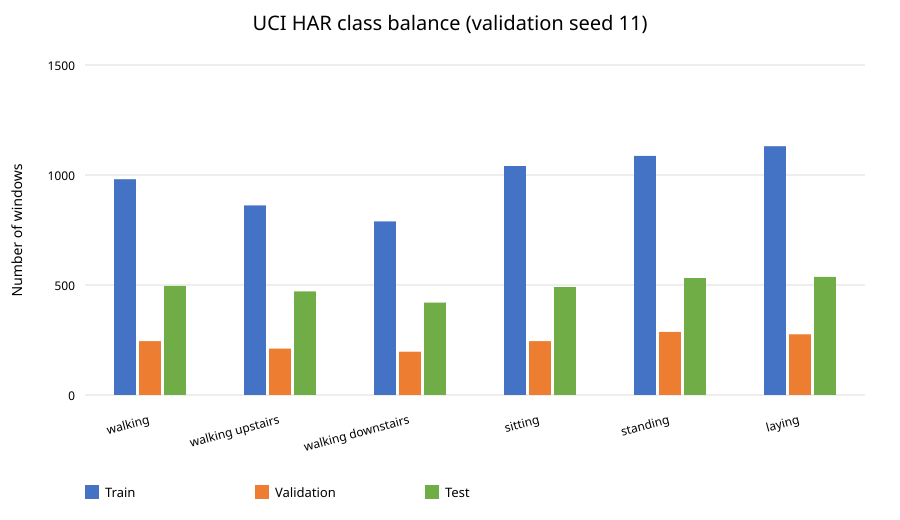

HAR loading, subject split, train-only normalization, and label checks passed.


In [2]:
from pathlib import Path
import os
import urllib.request
import zipfile


NOTEBOOK_DIR = Path.cwd()
if NOTEBOOK_DIR.name != 'problem1' and (NOTEBOOK_DIR / 'problem1').is_dir():
    NOTEBOOK_DIR = NOTEBOOK_DIR / 'problem1'
DATA_DIR = NOTEBOOK_DIR / 'data'
HAR_DIR = NOTEBOOK_DIR / 'har'
HAR_URL = 'https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip'
CHANNELS = (
    'body_acc_x', 'body_acc_y', 'body_acc_z',
    'body_gyro_x', 'body_gyro_y', 'body_gyro_z',
    'total_acc_x', 'total_acc_y', 'total_acc_z',
)
ACTIVITY_NAMES = ('walking', 'walking upstairs', 'walking downstairs', 'sitting', 'standing', 'laying')


def _safe_extract(zip_path, destination):
    destination = destination.resolve()
    with zipfile.ZipFile(zip_path) as archive:
        for member in archive.infolist():
            target = (destination / member.filename).resolve()
            if not target.is_relative_to(destination):
                raise ValueError(f'Unsafe path in dataset archive: {member.filename}')
            archive.extract(member, destination)


def _find_har_root(search_dir):
    for signal_dir in search_dir.rglob('Inertial Signals'):
        candidate = signal_dir.parent.parent
        if ((candidate / 'train' / 'y_train.txt').is_file()
                and (candidate / 'test' / 'y_test.txt').is_file()):
            return candidate
    return None


def load_har_arrays(dataset_root):
    def load_split(split):
        split_dir = dataset_root / split
        signal_dir = split_dir / 'Inertial Signals'
        x = np.stack([
            np.loadtxt(signal_dir / f'{channel}_{split}.txt', dtype=np.float32)
            for channel in CHANNELS
        ], axis=-1)
        y = np.loadtxt(split_dir / f'y_{split}.txt', dtype=np.int64)
        subjects = np.loadtxt(split_dir / f'subject_{split}.txt', dtype=np.int64)
        if x.ndim != 3 or x.shape[1:] != (128, 9):
            raise ValueError(f'Unexpected {split} signal shape: {x.shape}')
        if len(x) != len(y) or len(y) != len(subjects):
            raise ValueError(f'Mismatched {split} signals, labels and subjects')
        return x, y, subjects

    train_x, train_y, train_subjects = load_split('train')
    test_x, test_y, test_subjects = load_split('test')
    if not np.isin(train_y, np.arange(1, 7)).all() or not np.isin(test_y, np.arange(1, 7)).all():
        raise ValueError('HAR labels must be integers 1 through 6')
    return train_x, train_y, train_subjects, test_x, test_y, test_subjects


def prepare_har_data(seed, valid_subject_count=4):
    train_x, train_y, train_subjects, test_x, test_y, test_subjects = load_har_arrays(HAR_ROOT)
    unique_subjects = np.unique(train_subjects)
    if valid_subject_count >= len(unique_subjects):
        raise ValueError('Validation subjects must be fewer than training subjects')
    rng = np.random.default_rng(seed)
    valid_subjects = np.sort(rng.choice(unique_subjects, size=valid_subject_count, replace=False))
    is_valid = np.isin(train_subjects, valid_subjects)
    is_train = ~is_valid

    mean = train_x[is_train].mean(axis=(0, 1), keepdims=True)
    std = train_x[is_train].std(axis=(0, 1), keepdims=True)
    std = np.where(std < 1e-8, 1.0, std)

    data = {
        'train_x': ((train_x[is_train] - mean) / std).astype(np.float32),
        'train_y': train_y[is_train] - 1,
        'valid_x': ((train_x[is_valid] - mean) / std).astype(np.float32),
        'valid_y': train_y[is_valid] - 1,
        'test_x': ((test_x - mean) / std).astype(np.float32),
        'test_y': test_y - 1,
        'train_subjects': np.unique(train_subjects[is_train]),
        'valid_subjects': valid_subjects,
        'test_subjects': np.unique(test_subjects),
        'mean': mean.reshape(-1),
        'std': std.reshape(-1),
    }
    return data


os.chdir(NOTEBOOK_DIR)

HAR_ROOT = _find_har_root(HAR_DIR)
if HAR_ROOT is None:
    HAR_DIR.mkdir(parents=True, exist_ok=True)
    url = 'https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip'
    urllib.request.urlretrieve(url, 'har.zip')
    zipfile.ZipFile('har.zip').extractall('har')

    # The outer archive may contain a second archive with the actual dataset.
    for nested_archive in HAR_DIR.rglob('*.zip'):
        with zipfile.ZipFile(nested_archive) as archive:
            archive.extractall(nested_archive.parent)
    HAR_ROOT = _find_har_root(HAR_DIR)
if HAR_ROOT is None:
    raise FileNotFoundError(f'Could not locate UCI HAR Dataset under {HAR_DIR}')

har = prepare_har_data(seed=SEEDS[0])
print('Dataset root:', HAR_ROOT)
print('Train:', har['train_x'].shape, har['train_y'].shape)
print('Validation:', har['valid_x'].shape, har['valid_y'].shape,
      'held-out subjects:', har['valid_subjects'].tolist())
print('Official test:', har['test_x'].shape, har['test_y'].shape)
print('Input feature count:', har['train_x'].shape[-1], '| sequence length:', har['train_x'].shape[1])

class_counts = {
    'Train': np.bincount(har['train_y'], minlength=6),
    'Validation': np.bincount(har['valid_y'], minlength=6),
    'Test': np.bincount(har['test_y'], minlength=6),
}
# Write a dependency-free SVG chart so plotting works in CPU-only notebook environments.
from html import escape
from IPython.display import SVG, display

width, height = 900, 520
left, top, plot_width, plot_height = 85, 65, 780, 330
max_count = max(int(counts.max()) for counts in class_counts.values())
y_max = int(np.ceil(max_count / 500) * 500)
colors = {'Train': '#4472C4', 'Validation': '#ED7D31', 'Test': '#70AD47'}
svg_parts = [
    f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">',
    '<rect width="100%" height="100%" fill="white"/>',
    f'<text x="{width / 2}" y="30" text-anchor="middle" font-family="sans-serif" font-size="20">UCI HAR class balance (validation seed {SEEDS[0]})</text>',
]
for tick in range(0, y_max + 1, 500):
    y = top + plot_height - (tick / y_max) * plot_height
    svg_parts.append(f'<line x1="{left}" y1="{y:.1f}" x2="{left + plot_width}" y2="{y:.1f}" stroke="#dddddd"/>')
    svg_parts.append(f'<text x="{left - 10}" y="{y + 5:.1f}" text-anchor="end" font-family="sans-serif" font-size="12">{tick}</text>')
svg_parts.append(f'<text x="22" y="{top + plot_height / 2}" transform="rotate(-90 22 {top + plot_height / 2})" text-anchor="middle" font-family="sans-serif" font-size="14">Number of windows</text>')
slot = plot_width / 6
bar_width = 22
for class_index, activity in enumerate(ACTIVITY_NAMES):
    center = left + (class_index + 0.5) * slot
    for split_index, (split_name, counts) in enumerate(class_counts.items()):
        value = int(counts[class_index])
        bar_x = center + (split_index - 1) * (bar_width + 3) - bar_width / 2
        bar_h = (value / y_max) * plot_height
        bar_y = top + plot_height - bar_h
        svg_parts.append(f'<rect x="{bar_x:.1f}" y="{bar_y:.1f}" width="{bar_width}" height="{bar_h:.1f}" fill="{colors[split_name]}"/>')
    svg_parts.append(f'<text x="{center:.1f}" y="{top + plot_height + 28}" transform="rotate(-15 {center:.1f} {top + plot_height + 28})" text-anchor="end" font-family="sans-serif" font-size="12">{escape(activity)}</text>')
for index, (split_name, color) in enumerate(colors.items()):
    x = left + index * 170
    svg_parts.append(f'<rect x="{x}" y="{height - 35}" width="14" height="14" fill="{color}"/>')
    svg_parts.append(f'<text x="{x + 20}" y="{height - 23}" font-family="sans-serif" font-size="13">{split_name}</text>')
svg_parts.append('</svg>')
figure_dir = NOTEBOOK_DIR / 'figures'
figure_dir.mkdir(exist_ok=True)
figure_path = figure_dir / 'har_class_balance_seed_11.svg'
figure_path.write_text('\n'.join(svg_parts), encoding='utf-8')
display(SVG(filename=str(figure_path)))

assert har['train_x'].shape[1:] == (128, 9)
assert set(np.unique(har['train_y'])) <= set(range(6))
assert not set(har['train_subjects']) & set(har['valid_subjects'])
assert np.isfinite(har['train_x']).all() and np.isfinite(har['valid_x']).all() and np.isfinite(har['test_x']).all()
print('HAR loading, subject split, train-only normalization, and label checks passed.')

## Recurrent-cell compatibility and parameter counts

The parameter convention below combines the two PyTorch bias vectors into one effective bias, matching the assignment's hand derivation. PyTorch's stored module totals are also displayed for reconciliation.

In [3]:
torch.manual_seed(SEEDS[0])
assert check_backwards_compatibility(hidden_size=HIDDEN_SIZE)

counts = {
    name: count_recurrent_parameters(9, HIDDEN_SIZE, name.lower())
    for name in ('RNN', 'LSTM', 'GRU')
}
framework_counts = {
    'RNN': counts['RNN'] + HIDDEN_SIZE,
    'LSTM': counts['LSTM'] + 4 * HIDDEN_SIZE,
    'GRU': counts['GRU'] + 3 * HIDDEN_SIZE,
}
print('One-effective-bias counts:', counts)
print('PyTorch separate-bias counts:', framework_counts)

One-effective-bias counts: {'RNN': 1344, 'LSTM': 5376, 'GRU': 4032}
PyTorch separate-bias counts: {'RNN': 1376, 'LSTM': 5504, 'GRU': 4128}


## Adding-task generator checks for the selected seeds

Each generated sequence should have exactly two marker steps, one in each half, and a target equal to the sum of the marked values.

In [4]:
for seed in SEEDS:
    x, y = make_adding(n=32, T=200, seed=seed)
    assert validate_adding_problem(x, y)
    assert np.all((x[:, :, 1] > 0.5).sum(axis=1) == 2)
    print(f'seed={seed}: x={x.shape}, y={y.shape}, invariants=passed')

seed=11: x=(32, 200, 2), y=(32,), invariants=passed
seed=23: x=(32, 200, 2), y=(32,), invariants=passed
seed=42: x=(32, 200, 2), y=(32,), invariants=passed


In [5]:
import time, copy, math, random
import torch.nn.functional as F
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, confusion_matrix

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
ROOT = NOTEBOOK_DIR.parent
RESULTS_CSV = ROOT / 'results.csv'
FIG = NOTEBOOK_DIR / 'figures'; FIG.mkdir(exist_ok=True)
COLUMNS = ['problem','model','seed','seq_len','test_acc','macro_f1','test_mse','params',
           'sec_per_epoch','val_loss_nats','bits_per_char','notes']
HAR_EPOCHS, ADD_EPOCHS, BATCH = 20, 30, 64
KINDS = ['RNN', 'LSTM', 'GRU']
print('device:', DEVICE)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)

def log_row(**kw):
    """Append/replace one row of results.csv (key = problem, model, seed, seq_len, notes)."""
    row = {c: ('' if kw.get(c) is None else str(kw.get(c))) for c in COLUMNS}
    df = (pd.read_csv(RESULTS_CSV, dtype=str, keep_default_na=False)
          if RESULTS_CSV.exists() else pd.DataFrame(columns=COLUMNS))
    same = np.ones(len(df), dtype=bool)
    for k in ['problem', 'model', 'seed', 'seq_len', 'notes']:
        same &= (df[k] == row[k]).values
    df = pd.concat([df[~same], pd.DataFrame([row])], ignore_index=True)[COLUMNS]
    df.to_csv(RESULTS_CSV, index=False)

def sync():
    if torch.cuda.is_available(): torch.cuda.synchronize()

device: cuda


## Task 2 - RNN, LSTM and GRU cells from scratch

Each cell uses only matrix operations on its own parameters (`W_ih`, `W_hh`, `b_ih`, `b_hh`, PyTorch layout, gate order i,f,g,o for LSTM and r,z,n for GRU). Weights are copied from the library layer and the outputs are compared within 1e-5. Shapes: `x_t` is (B, d), `h` and `c` are (B, h), `W_ih` is (G*h, d), `W_hh` is (G*h, h) with G = 1, 4, 3 gates.

In [6]:
class _CellBase(nn.Module):
    gates = 1
    def __init__(self, d, h):
        super().__init__()
        self.d, self.h = d, h
        G = self.gates
        self.W_ih = nn.Parameter(torch.empty(G * h, d)); self.W_hh = nn.Parameter(torch.empty(G * h, h))
        self.b_ih = nn.Parameter(torch.empty(G * h));     self.b_hh = nn.Parameter(torch.empty(G * h))
        bound = 1.0 / math.sqrt(h)
        for p in self.parameters(): nn.init.uniform_(p, -bound, bound)
    @torch.no_grad()
    def load_from(self, layer):
        self.W_ih.copy_(layer.weight_ih_l0); self.W_hh.copy_(layer.weight_hh_l0)
        self.b_ih.copy_(layer.bias_ih_l0);   self.b_hh.copy_(layer.bias_hh_l0)

class MyRNNCell(_CellBase):
    gates = 1
    def forward(self, x, h):                       # x (B,d), h (B,h) -> (B,h)
        return torch.tanh(x @ self.W_ih.T + self.b_ih + h @ self.W_hh.T + self.b_hh)

class MyLSTMCell(_CellBase):
    gates = 4
    def forward(self, x, state):                   # state = (h, c), each (B,h)
        h, c = state
        g = x @ self.W_ih.T + self.b_ih + h @ self.W_hh.T + self.b_hh      # (B,4h)
        i, f, gg, o = g.chunk(4, dim=-1)                                    # each (B,h)
        i, f, o, gg = torch.sigmoid(i), torch.sigmoid(f), torch.sigmoid(o), torch.tanh(gg)
        c = f * c + i * gg
        return o * torch.tanh(c), c

class MyGRUCell(_CellBase):
    gates = 3
    def forward(self, x, h):                       # x (B,d), h (B,h)
        gi = x @ self.W_ih.T + self.b_ih            # (B,3h)  input part  [r, z, n]
        gh = h @ self.W_hh.T + self.b_hh            # (B,3h)  hidden part
        ir, iz, inn = gi.chunk(3, dim=-1); hr, hz, hn = gh.chunk(3, dim=-1)
        r = torch.sigmoid(ir + hr); z = torch.sigmoid(iz + hz)
        n = torch.tanh(inn + r * hn)                # reset gate multiplies the hidden-side term (PyTorch convention)
        return (1 - z) * n + z * h

def run_cell(cell, x, h0, c0=None):
    """Unroll a cell over x (B,T,d). Returns outputs (B,T,h)."""
    outs, h, c = [], h0, c0
    for t in range(x.size(1)):
        if isinstance(cell, MyLSTMCell): h, c = cell(x[:, t], (h, c))
        else: h = cell(x[:, t], h)
        outs.append(h)
    return torch.stack(outs, dim=1)

# ---- unit tests: match nn.RNN / nn.LSTM / nn.GRU within 1e-5 (d=9, h=32 and h=64) ----
torch.manual_seed(0)
for hid in (HIDDEN_SIZE, 64):
    xb = torch.randn(8, 20, 9); h0 = torch.randn(8, hid); c0 = torch.randn(8, hid)
    with torch.no_grad():
        lib = nn.RNN(9, hid, batch_first=True); mine = MyRNNCell(9, hid); mine.load_from(lib)
        ref, _ = lib(xb, h0[None]); assert torch.allclose(run_cell(mine, xb, h0), ref, atol=1e-5)
        lib = nn.LSTM(9, hid, batch_first=True); mine = MyLSTMCell(9, hid); mine.load_from(lib)
        ref, _ = lib(xb, (h0[None], c0[None])); assert torch.allclose(run_cell(mine, xb, h0, c0), ref, atol=1e-5)
        lib = nn.GRU(9, hid, batch_first=True); mine = MyGRUCell(9, hid); mine.load_from(lib)
        ref, _ = lib(xb, h0[None]); assert torch.allclose(run_cell(mine, xb, h0), ref, atol=1e-5)
print('MyRNNCell, MyLSTMCell, MyGRUCell match the library layers within 1e-5 (h=32 and h=64).')

# ---- parameter counts: hand formula  G*(d*h + h*h + h)  vs code; PyTorch keeps two bias vectors: G*(d*h + h*h + 2h)
for hid in (64, HIDDEN_SIZE):
    for name, cls, G in (('RNN', MyRNNCell, 1), ('LSTM', MyLSTMCell, 4), ('GRU', MyGRUCell, 3)):
        hand_one_bias = G * (9 * hid + hid * hid + hid)
        hand_two_bias = G * (9 * hid + hid * hid + 2 * hid)
        code = sum(p.numel() for p in cls(9, hid).parameters())
        lib = sum(p.numel() for p in {'RNN': nn.RNN, 'LSTM': nn.LSTM, 'GRU': nn.GRU}[name](9, hid).parameters())
        assert code == lib == hand_two_bias and hand_two_bias - hand_one_bias == G * hid
        print(f'h={hid:3d} {name:4s} one-bias(hand)={hand_one_bias:6d}  two-bias(code=PyTorch)={code:6d}')
assert 1 * (9*64 + 64*64 + 64) == 4736 and 4 * (9*64 + 64*64 + 64) == 18944 and 3 * (9*64 + 64*64 + 64) == 14208

MyRNNCell, MyLSTMCell, MyGRUCell match the library layers within 1e-5 (h=32 and h=64).
h= 64 RNN  one-bias(hand)=  4736  two-bias(code=PyTorch)=  4800
h= 64 LSTM one-bias(hand)= 18944  two-bias(code=PyTorch)= 19200
h= 64 GRU  one-bias(hand)= 14208  two-bias(code=PyTorch)= 14400
h= 32 RNN  one-bias(hand)=  1344  two-bias(code=PyTorch)=  1376
h= 32 LSTM one-bias(hand)=  5376  two-bias(code=PyTorch)=  5504
h= 32 GRU  one-bias(hand)=  4032  two-bias(code=PyTorch)=  4128


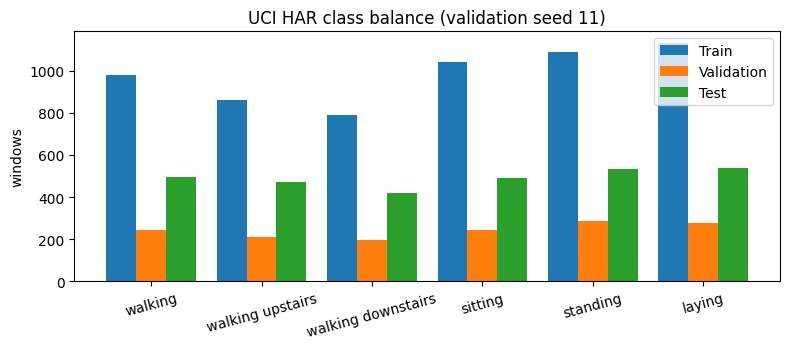

In [7]:
# class-balance figure (PNG for the report; the SVG from the earlier cell is kept too)
fig, ax = plt.subplots(figsize=(8, 3.6)); w = 0.27
for j, (nm, cnt) in enumerate(class_counts.items()):
    ax.bar(np.arange(6) + (j - 1) * w, cnt, w, label=nm)
ax.set_xticks(range(6)); ax.set_xticklabels(ACTIVITY_NAMES, rotation=15)
ax.set_ylabel('windows'); ax.set_title(f'UCI HAR class balance (validation seed {SEEDS[0]})'); ax.legend()
fig.tight_layout(); fig.savefig(FIG / 'har_class_balance.png', dpi=150); plt.show()

## Task 3 - HAR classification (RNN / LSTM / GRU, 3 seeds)

In [8]:
_raw_load = load_har_arrays; _raw_cache = {}
def load_har_arrays(root):                      # cache the slow np.loadtxt pass across seeds
    if root not in _raw_cache: _raw_cache[root] = _raw_load(root)
    return _raw_cache[root]

_har_cache = {}
def har_tensors(seed):
    if seed not in _har_cache:
        d = prepare_har_data(seed)
        _har_cache[seed] = {k: torch.tensor(d[k]).to(DEVICE) for k in
                            ('train_x','train_y','valid_x','valid_y','test_x','test_y')}
    return _har_cache[seed]

class SeqClassifier(nn.Module):
    """Library recurrent layer + linear head on the last hidden state."""
    def __init__(self, kind, d_in, h, n_out):
        super().__init__()
        self.rnn = {'RNN': nn.RNN, 'LSTM': nn.LSTM, 'GRU': nn.GRU}[kind](d_in, h, batch_first=True)
        self.head = nn.Linear(h, n_out)
    def forward(self, x):                        # x (B,T,d) -> logits (B,n_out)
        out, _ = self.rnn(x)                     # out (B,T,h)
        return self.head(out[:, -1])

@torch.no_grad()
def predict(model, x, bs=512):
    model.eval()
    return torch.cat([model(x[i:i + bs]).argmax(-1) for i in range(0, len(x), bs)]).cpu().numpy()

def train_har(kind, seed, h=HIDDEN_SIZE, epochs=HAR_EPOCHS, bs=BATCH, lr=1e-3, clip=1.0):
    set_seed(seed); D = har_tensors(seed)
    model = SeqClassifier(kind, 9, h, 6).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    best_val, best_state, times = -1.0, None, []
    for ep in range(epochs):
        model.train(); sync(); t0 = time.time()
        perm = torch.randperm(len(D['train_x']), device=DEVICE)
        for i in range(0, len(perm), bs):
            idx = perm[i:i + bs]
            loss = F.cross_entropy(model(D['train_x'][idx]), D['train_y'][idx])
            opt.zero_grad(); loss.backward()
            if clip: nn.utils.clip_grad_norm_(model.parameters(), clip)
            opt.step()
        sync(); times.append(time.time() - t0)
        va = float((predict(model, D['valid_x']) == D['valid_y'].cpu().numpy()).mean())
        if va > best_val: best_val, best_state = va, copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    yte = D['test_y'].cpu().numpy(); pred = predict(model, D['test_x'])
    return dict(kind=kind, seed=seed, h=h, test_acc=float((pred == yte).mean()),
                macro_f1=float(f1_score(yte, pred, average='macro')), val_acc=best_val,
                params=sum(p.numel() for p in model.parameters()),
                sec_per_epoch=float(np.mean(times)), pred=pred, y=yte)

RNN  seed=11  acc=0.8073  f1=0.8091  0.27s/epoch
RNN  seed=23  acc=0.8660  f1=0.8641  0.20s/epoch
RNN  seed=42  acc=0.7615  f1=0.7572  0.22s/epoch
LSTM seed=11  acc=0.8833  f1=0.8841  0.23s/epoch
LSTM seed=23  acc=0.8700  f1=0.8695  0.23s/epoch
LSTM seed=42  acc=0.8660  f1=0.8637  0.25s/epoch
GRU  seed=11  acc=0.8833  f1=0.8856  0.21s/epoch
GRU  seed=23  acc=0.8914  f1=0.8925  0.22s/epoch
GRU  seed=42  acc=0.8921  f1=0.8917  0.24s/epoch
      acc_mean  acc_std  f1_mean  f1_std  params  sec_per_epoch
kind                                                           
RNN     0.8116   0.0524   0.8101  0.0535    1574         0.2303
LSTM    0.8731   0.0090   0.8725  0.0105    5702         0.2379
GRU     0.8889   0.0049   0.8899  0.0038    4326         0.2235


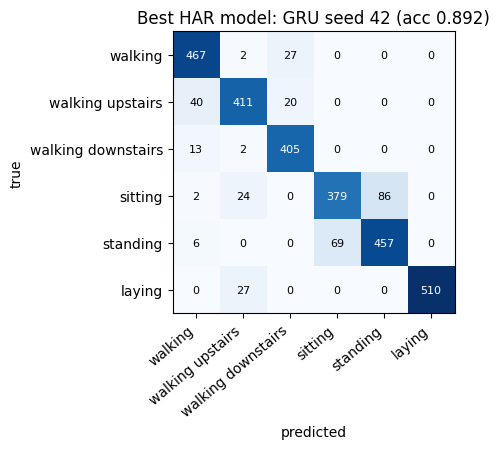

In [9]:
HAR_RES = []
for kind in KINDS:
    for seed in SEEDS:
        r = train_har(kind, seed); HAR_RES.append(r)
        log_row(problem='P1', model=kind, seed=seed, seq_len=128, test_acc=r['test_acc'], macro_f1=r['macro_f1'],
                params=r['params'], sec_per_epoch=r['sec_per_epoch'], notes=f'HAR main h={HIDDEN_SIZE} epochs={HAR_EPOCHS}')
        print(f"{kind:4s} seed={seed}  acc={r['test_acc']:.4f}  f1={r['macro_f1']:.4f}  {r['sec_per_epoch']:.2f}s/epoch")

har_df = pd.DataFrame([{k: v for k, v in r.items() if k not in ('pred', 'y')} for r in HAR_RES])
har_table = har_df.groupby('kind').agg(acc_mean=('test_acc','mean'), acc_std=('test_acc','std'),
            f1_mean=('macro_f1','mean'), f1_std=('macro_f1','std'),
            params=('params','first'), sec_per_epoch=('sec_per_epoch','mean')).loc[KINDS]
print(har_table.round(4))

best = max(HAR_RES, key=lambda r: r['test_acc'])
cm = confusion_matrix(best['y'], best['pred'])
fig, ax = plt.subplots(figsize=(5.2, 4.6)); im = ax.imshow(cm, cmap='Blues')
ax.set_xticks(range(6)); ax.set_yticks(range(6))
ax.set_xticklabels(ACTIVITY_NAMES, rotation=40, ha='right'); ax.set_yticklabels(ACTIVITY_NAMES)
for i in range(6):
    for j in range(6): ax.text(j, i, cm[i, j], ha='center', va='center', color='white' if cm[i, j] > cm.max() / 2 else 'black', fontsize=8)
ax.set_xlabel('predicted'); ax.set_ylabel('true'); ax.set_title(f"Best HAR model: {best['kind']} seed {best['seed']} (acc {best['test_acc']:.3f})")
fig.tight_layout(); fig.savefig(FIG / 'har_confusion_matrix.png', dpi=150); plt.show()

## Task 4 - Adding problem, T = 50, 100, 200, 400

In [ ]:
class AddModel(nn.Module):
    def __init__(self, kind, h=HIDDEN_SIZE, forget_bias=None):
        super().__init__()
        self.kind = kind
        self.rnn = {'RNN': nn.RNN, 'LSTM': nn.LSTM, 'GRU': nn.GRU}[kind](2, h, batch_first=True)
        self.head = nn.Linear(h, 1)
    def forward(self, x):                        # x (B,T,2) -> (B,)
        out, _ = self.rnn(x)
        return self.head(out[:, -1]).squeeze(-1)

_add_data = {}
def adding_data(T):
    if T not in _add_data:
        _add_data[T] = [tuple(torch.tensor(a).to(DEVICE) for a in make_adding(n, T, s)) for n, s in ((10000, 0), (1000, 1), (1000, 2))]
        for x, y in _add_data[T]: assert validate_adding_problem(x.cpu().numpy(), y.cpu().numpy())
    return _add_data[T]

@torch.no_grad()
def mse_of(model, x, y, bs=500):
    model.eval()
    return float(sum(F.mse_loss(model(x[i:i+bs]), y[i:i+bs], reduction='sum').item() for i in range(0, len(x), bs)) / len(x))

def train_adding(kind, T, seed, h=HIDDEN_SIZE, epochs=ADD_EPOCHS, bs=BATCH, lr=1e-3, clip=1.0):
    set_seed(seed); (xtr, ytr), (xva, yva), (xte, yte) = adding_data(T)
    model = AddModel(kind, h).to(DEVICE); opt = torch.optim.Adam(model.parameters(), lr=lr)
    tr_curve, va_curve, times = [], [], []
    best_val, best_state = 1e9, copy.deepcopy(model.state_dict())
    for ep in range(epochs):
        model.train(); sync(); t0 = time.time(); perm = torch.randperm(len(xtr), device=DEVICE); tot = 0.0
        for i in range(0, len(perm), bs):
            idx = perm[i:i + bs]; loss = F.mse_loss(model(xtr[idx]), ytr[idx])
            opt.zero_grad(); loss.backward()
            if clip: nn.utils.clip_grad_norm_(model.parameters(), clip)
            opt.step(); tot += loss.item() * len(idx)
        sync(); times.append(time.time() - t0)
        tr_curve.append(tot / len(xtr)); v = mse_of(model, xva, yva); va_curve.append(v)
        if v < best_val: best_val, best_state = v, copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    return dict(kind=kind, T=T, seed=seed, test_mse=mse_of(model, xte, yte), train_curve=tr_curve, val_curve=va_curve,
                params=sum(p.numel() for p in model.parameters()), sec_per_epoch=float(np.mean(times)), model=model)

T= 50 RNN  seed=11  test MSE=0.1326
T= 50 RNN  seed=23  test MSE=0.0872
T= 50 RNN  seed=42  test MSE=0.1522
T= 50 LSTM seed=11  test MSE=0.0044
T= 50 LSTM seed=23  test MSE=0.0043
T= 50 LSTM seed=42  test MSE=0.0064
T= 50 GRU  seed=11  test MSE=0.0003
T= 50 GRU  seed=23  test MSE=0.0007
T= 50 GRU  seed=42  test MSE=0.0004
T=100 RNN  seed=11  test MSE=0.1704
T=100 RNN  seed=23  test MSE=0.1705
T=100 RNN  seed=42  test MSE=0.1683
T=100 LSTM seed=11  test MSE=0.1008
T=100 LSTM seed=23  test MSE=0.1352
T=100 LSTM seed=42  test MSE=0.1692
T=100 GRU  seed=11  test MSE=0.0004
T=100 GRU  seed=23  test MSE=0.0007
T=100 GRU  seed=42  test MSE=0.0008
T=200 RNN  seed=11  test MSE=0.1685
T=200 RNN  seed=23  test MSE=0.1684
T=200 RNN  seed=42  test MSE=0.1687
T=200 LSTM seed=11  test MSE=0.1685
T=200 LSTM seed=23  test MSE=0.1685
T=200 LSTM seed=42  test MSE=0.1684
T=200 GRU  seed=11  test MSE=0.0006
T=200 GRU  seed=23  test MSE=0.0006
T=200 GRU  seed=42  test MSE=0.0007
T=400 RNN  seed=11  test MSE

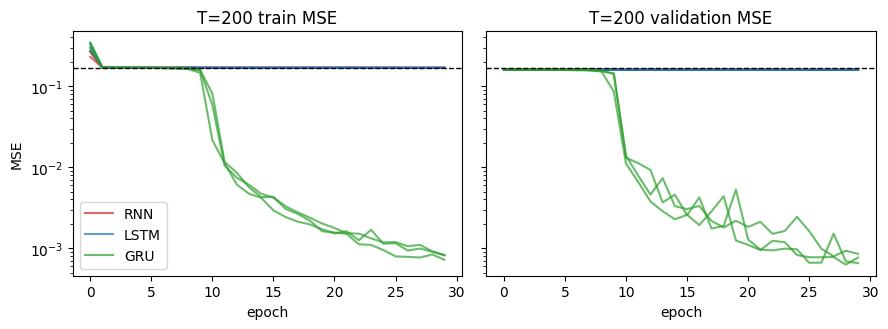

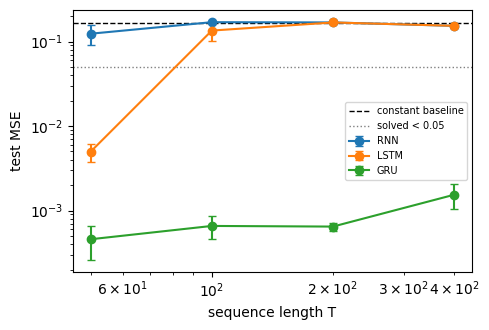

In [11]:
LENGTHS = [50, 100, 200, 400]; BASELINE = 0.167; SOLVED = 0.05
ADD_RES = {}
for T in LENGTHS:
    for kind in KINDS:
        for seed in SEEDS:
            r = train_adding(kind, T, seed); ADD_RES[(kind, T, seed)] = r
            log_row(problem='P1', model=kind, seed=seed, seq_len=T, test_mse=r['test_mse'], params=r['params'],
                    sec_per_epoch=r['sec_per_epoch'], notes=f'Adding main h={HIDDEN_SIZE} epochs={ADD_EPOCHS} clip=1.0')
            print(f"T={T:3d} {kind:4s} seed={seed}  test MSE={r['test_mse']:.4f}")

rows = [dict(model=k, T=T, seed=s, mse=ADD_RES[(k, T, s)]['test_mse']) for (k, T, s) in ADD_RES]
add_df = pd.DataFrame(rows)
mse_table = add_df.groupby(['model', 'T'])['mse'].agg(['mean', 'std']).unstack('T').loc[KINDS]
solved = add_df.assign(solved=add_df.mse < SOLVED).groupby(['model', 'T'])['solved'].sum().unstack('T').loc[KINDS]
print('Test MSE (mean, std) - baseline ~0.167'); print(mse_table.round(4)); print('Solved runs out of 3 (MSE < 0.05)'); print(solved)

# learning curves at T=200
fig, axs = plt.subplots(1, 2, figsize=(9, 3.4), sharey=True)
for ax, key, ttl in ((axs[0], 'train_curve', 'train MSE'), (axs[1], 'val_curve', 'validation MSE')):
    for kind, col in zip(KINDS, ('tab:red', 'tab:blue', 'tab:green')):
        for s in SEEDS:
            ax.plot(ADD_RES[(kind, 200, s)][key], color=col, alpha=.7, label=kind if s == SEEDS[0] else None)
    ax.axhline(BASELINE, ls='--', c='k', lw=1); ax.set_title(f'T=200 {ttl}'); ax.set_xlabel('epoch'); ax.set_yscale('log')
axs[0].set_ylabel('MSE'); axs[0].legend(); fig.tight_layout(); fig.savefig(FIG / 'adding_curves_T200.png', dpi=150); plt.show()

# MSE against T
fig, ax = plt.subplots(figsize=(5, 3.4))
for kind in KINDS:
    m = [mse_table.loc[kind, ('mean', T)] for T in LENGTHS]; sd = [mse_table.loc[kind, ('std', T)] for T in LENGTHS]
    ax.errorbar(LENGTHS, m, yerr=sd, marker='o', capsize=3, label=kind)
ax.axhline(BASELINE, ls='--', c='k', lw=1, label='constant baseline'); ax.axhline(SOLVED, ls=':', c='gray', lw=1, label='solved < 0.05')
ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlabel('sequence length T'); ax.set_ylabel('test MSE'); ax.legend(fontsize=7)
fig.tight_layout(); fig.savefig(FIG / 'adding_mse_vs_T.png', dpi=150); plt.show()

## Task 5(a) - gradient norm against time step (T = 100)

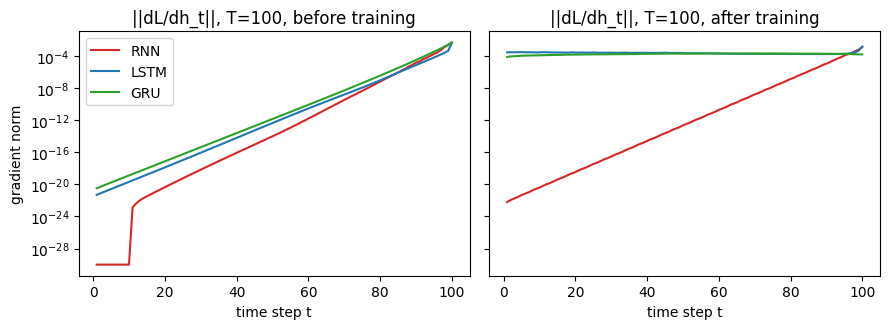

In [12]:
def grad_norm_profile(kind, lib_model, T, seed=1):
    """||dL/dh_t|| for t=1..T, averaged over 256 validation sequences. Uses MY cells (unrolled) so that
    h_t.grad is the TOTAL gradient flowing back through the recurrence (cuDNN outputs would only give the direct gradient)."""
    cell = {'RNN': MyRNNCell, 'LSTM': MyLSTMCell, 'GRU': MyGRUCell}[kind](2, lib_model.rnn.hidden_size).to(DEVICE)
    cell.load_from(lib_model.rnn)
    x, y = [torch.tensor(a).to(DEVICE) for a in make_adding(256, T, seed)]
    h = torch.zeros(256, cell.h, device=DEVICE); c = torch.zeros_like(h); hs = []
    for t in range(T):
        if kind == 'LSTM': h, c = cell(x[:, t], (h, c))
        else: h = cell(x[:, t], h)
        h.retain_grad(); hs.append(h)
    loss = F.mse_loss(lib_model.head(h).squeeze(-1), y)
    lib_model.zero_grad(); loss.backward()
    return np.array([hh.grad.norm(dim=-1).mean().item() for hh in hs])

GT = 100
fig, axs = plt.subplots(1, 2, figsize=(9, 3.4), sharey=True)
for kind, col in zip(KINDS, ('tab:red', 'tab:blue', 'tab:green')):
    set_seed(SEEDS[0]); fresh = AddModel(kind).to(DEVICE)                       # before training (same init as the trained run)
    axs[0].plot(np.arange(1, GT + 1), np.maximum(grad_norm_profile(kind, fresh, GT), 1e-30), c=col, label=kind)
    trained = ADD_RES[(kind, GT, SEEDS[0])]['model']                            # after training at T=100
    axs[1].plot(np.arange(1, GT + 1), np.maximum(grad_norm_profile(kind, trained, GT), 1e-30), c=col, label=kind)
for ax, ttl in zip(axs, ('before training', 'after training')):
    ax.set_yscale('log'); ax.set_xlabel('time step t'); ax.set_title(f'||dL/dh_t||, T=100, {ttl}')
axs[0].set_ylabel('gradient norm'); axs[0].legend(); fig.tight_layout(); fig.savefig(FIG / 'grad_norms_T100.png', dpi=150); plt.show()

## Task 5(b) - hidden-size sweep on HAR (LSTM, GRU)

          acc_mean  acc_std  params     sec
kind h                                     
GRU  16     0.8749   0.0171    1398  0.2265
     32     0.8889   0.0049    4326  0.2326
     64     0.8842   0.0081   14790  0.2312
     128    0.8996   0.0073   54150  0.2315
LSTM 16     0.8651   0.0242    1830  0.2341
     32     0.8731   0.0090    5702  0.2392
     64     0.8878   0.0087   19590  0.2393
     128    0.9005   0.0137   71942  0.3326


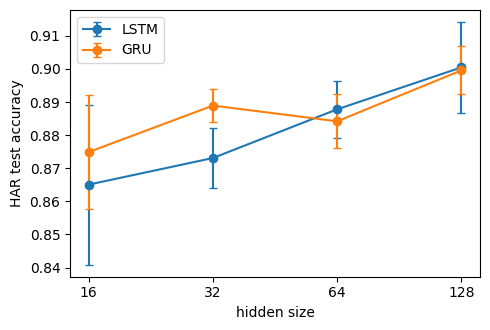

In [13]:
SWEEP = [16, 32, 64, 128]; SW_RES = []
for kind in ('LSTM', 'GRU'):
    for h in SWEEP:
        for seed in SEEDS:
            r = train_har(kind, seed, h=h); SW_RES.append(r)
            log_row(problem='P1', model=kind, seed=seed, seq_len=128, test_acc=r['test_acc'], macro_f1=r['macro_f1'],
                    params=r['params'], sec_per_epoch=r['sec_per_epoch'], notes=f'HAR hidden sweep h={h}')
sw = pd.DataFrame([{k: v for k, v in r.items() if k not in ('pred', 'y')} for r in SW_RES])
sw_t = sw.groupby(['kind', 'h']).agg(acc_mean=('test_acc', 'mean'), acc_std=('test_acc', 'std'), params=('params', 'first'), sec=('sec_per_epoch', 'mean'))
print(sw_t.round(4))
fig, ax = plt.subplots(figsize=(5, 3.4))
for kind in ('LSTM', 'GRU'):
    t = sw_t.loc[kind]; ax.errorbar(t.index, t.acc_mean, yerr=t.acc_std, marker='o', capsize=3, label=kind)
ax.set_xscale('log', base=2); ax.set_xticks(SWEEP); ax.set_xticklabels(SWEEP); ax.set_xlabel('hidden size'); ax.set_ylabel('HAR test accuracy'); ax.legend()
fig.tight_layout(); fig.savefig(FIG / 'hidden_sweep.png', dpi=150); plt.show()

## Task 5(c) - clipping ablation (even student ID): vanilla RNN, T = 200

clip 1.0  test MSE 0.1685 +- 0.0002   per seed [0.1685 0.1684 0.1687]
no clip   test MSE 0.1683 +- 0.0001   per seed [0.1684 0.1682 0.1684]


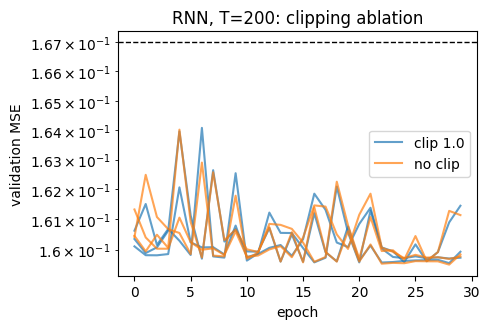

In [14]:
# (c) EVEN student ID (...788): gradient clipping 1.0 vs none, vanilla RNN, T = 200, 3 seeds
ABL_RES = {'clip 1.0': [ADD_RES[('RNN', 200, s)] for s in SEEDS], 'no clip': []}
for s in SEEDS:
    r = train_adding('RNN', 200, s, clip=None); ABL_RES['no clip'].append(r)
    log_row(problem='P1', model='RNN', seed=s, seq_len=200, test_mse=r['test_mse'], params=r['params'],
            sec_per_epoch=r['sec_per_epoch'], notes=f'Ablation clip=none h={HIDDEN_SIZE} epochs={ADD_EPOCHS}')
for name, rs in ABL_RES.items():
    m = [r['test_mse'] for r in rs]; print(f'{name:9s} test MSE {np.mean(m):.4f} +- {np.std(m, ddof=1):.4f}   per seed {np.round(m, 4)}')
fig, ax = plt.subplots(figsize=(5, 3.4))
for (name, rs), col in zip(ABL_RES.items(), ('tab:blue', 'tab:orange')):
    for j, r in enumerate(rs): ax.plot(r['val_curve'], c=col, alpha=.7, label=name if j == 0 else None)
ax.axhline(BASELINE, ls='--', c='k', lw=1); ax.set_yscale('log'); ax.set_xlabel('epoch'); ax.set_ylabel('validation MSE'); ax.set_title('RNN, T=200: clipping ablation'); ax.legend()
fig.tight_layout(); fig.savefig(FIG / 'ablation_clip.png', dpi=150); plt.show()

## (d) One-page analysis

*Write this after the run, using the tables and figures above (it is copied into the report).* Cover: (1) what the gradient-norm plot says about memory (does the RNN gradient vanish with distance from the output? do LSTM/GRU keep it flatter?); (2) where each model fails as T grows (which T the plain RNN stalls near 0.167; the solved-run table); (3) the accuracy - parameters - seconds/epoch trade-off from the HAR table; (4) the wearable recommendation with reasons taken from those tables; (5) what the clipping ablation shows.